# Machine Learning - Assignment 2
## Dry Bean Multi-Class Classification

**Name:** Nikilesh S V  
**BITS ID:** 2026AJ05026

This notebook implements and compares **five classification models** on the UCI
**Dry Bean** dataset, computing six evaluation metrics for each, and saves the trained
models + preprocessing artefacts for the Streamlit deployment.

**Dataset:** UCI Dry Bean Dataset - 13,611 instances, 16 numeric features, 7 bean classes.


## 1. Imports

In [1]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Imports ready.")

Imports ready.


## 2. Load the dataset

In [2]:
# Locate the dataset relative to the project root, whether this notebook is run
# from the project folder or from the notebook/ subfolder.
candidates = [
    "_drybean/DryBeanDataset/Dry_Bean_Dataset.xlsx",
    "../_drybean/DryBeanDataset/Dry_Bean_Dataset.xlsx",
]
data_path = next((p for p in candidates if os.path.exists(p)), candidates[0])
df = pd.read_excel(data_path)
print("Loaded:", data_path)
print("Shape:", df.shape, "->", df.shape[1]-1, "features,", df.shape[0], "instances")
df.head()

Loaded: ../_drybean/DryBeanDataset/Dry_Bean_Dataset.xlsx
Shape: (13611, 17) -> 16 features, 13611 instances


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 3. Exploratory Data Analysis

In [3]:
print("Feature columns:", list(df.columns[:-1]))
print("\nTarget classes:")
print(df["Class"].value_counts())
print("\nMissing values:", int(df.isnull().sum().sum()))
df.describe().T

Feature columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Target classes:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


C:\Users\in438e\AppData\Local\Temp\ipykernel_48028\4273745098.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index, palette="viridis")


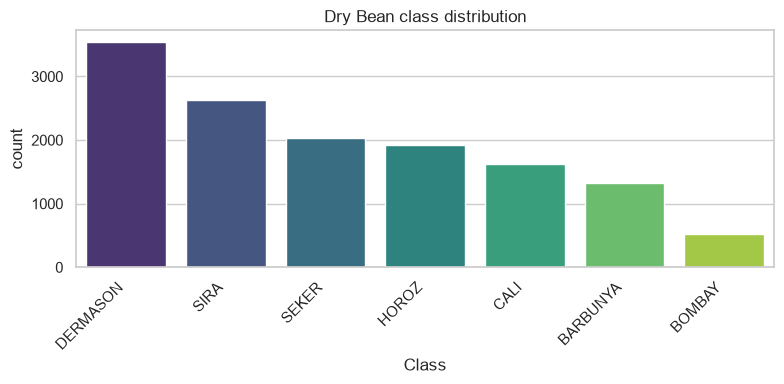

In [4]:
# Class distribution
plt.figure(figsize=(8,4))
sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index, palette="viridis")
plt.title("Dry Bean class distribution")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

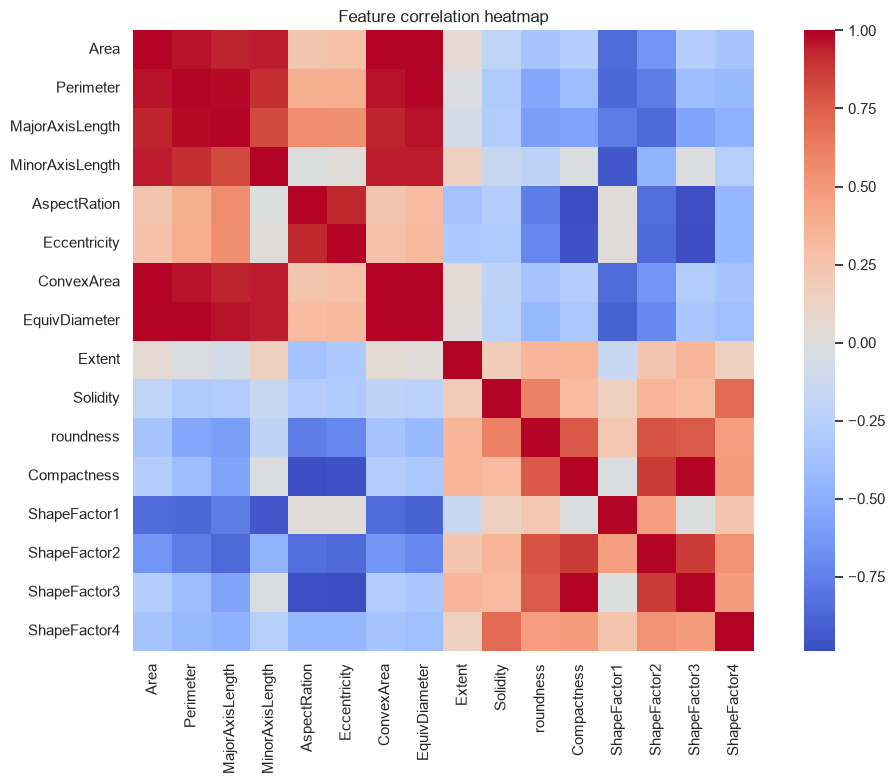

In [5]:
# Correlation heatmap of the 16 features
plt.figure(figsize=(11,8))
sns.heatmap(df.drop(columns=["Class"]).corr(), cmap="coolwarm", center=0,
            annot=False, square=True)
plt.title("Feature correlation heatmap")
plt.tight_layout(); plt.show()

## 4. Preprocessing

- Encode the 7 string class labels into integers with `LabelEncoder`.
- Stratified 80/20 train-test split (preserves class balance).
- Standardise the features with `StandardScaler` (fit on train only) - important for
  KNN, SVM and Logistic Regression.


In [6]:
X = df.drop(columns=["Class"])
y_raw = df["Class"]
feature_names = list(X.columns)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)
n_classes = len(label_encoder.classes_)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print("Train:", X_train_scaled.shape, " Test:", X_test_scaled.shape, " Classes:", n_classes)

Train: (10888, 16)  Test: (2723, 16)  Classes: 7


## 5. Define the five classifiers

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
}
models

{'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
 'Decision Tree': DecisionTreeClassifier(random_state=42),
 'KNN': KNeighborsClassifier(n_neighbors=7),
 'Naive Bayes': GaussianNB(),
 'Support Vector Machine': SVC(probability=True, random_state=42)}

## 6. Train, evaluate and save each model

Six metrics are computed per model: **Accuracy, AUC (macro one-vs-rest), Precision,
Recall, F1 (macro), MCC**. Each fitted model is saved to `model/`.


In [8]:
ROOT = ".." if os.path.basename(os.getcwd()) == "notebook" else "."
def evaluate(model, X_test, y_test, n_classes):
    y_pred = model.predict(X_test)
    try:
        y_proba = model.predict_proba(X_test)
        auc = (roc_auc_score(y_test, y_proba[:,1]) if n_classes==2
               else roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"))
    except Exception:
        auc = np.nan
    avg = "binary" if n_classes==2 else "macro"
    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_test, y_pred, average=avg, zero_division=0),
        "Recall": recall_score(y_test, y_pred, average=avg, zero_division=0),
        "F1": f1_score(y_test, y_pred, average=avg, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred),
    }

os.makedirs(f"{ROOT}/model", exist_ok=True)
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    results[name] = evaluate(model, X_test_scaled, y_test, n_classes)
    joblib.dump(model, f"{ROOT}/model/{name.lower().replace(' ','_')}.joblib")
    print("trained + saved:", name)

joblib.dump(scaler, f"{ROOT}/model/scaler.joblib")
joblib.dump(label_encoder, f"{ROOT}/model/label_encoder.joblib")
with open(f"{ROOT}/model/metadata.json","w") as f:
    json.dump({"feature_names": feature_names, "target": "Class",
               "classes": list(label_encoder.classes_), "n_classes": n_classes,
               "model_files": {n: n.lower().replace(' ','_')+'.joblib' for n in models}}, f, indent=2)
print("Artefacts saved.")

trained + saved: Logistic Regression


trained + saved: Decision Tree


trained + saved: KNN
trained + saved: Naive Bayes


C:\Python3.14\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


trained + saved: Support Vector Machine
Artefacts saved.


## 7. Comparison table (all 5 models, 6 metrics)

In [9]:
comparison = pd.DataFrame(results).T[["Accuracy","AUC","Precision","Recall","F1","MCC"]].round(4)
comparison

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9214,0.9948,0.9354,0.9321,0.9335,0.9050
Decision Tree,0.8920,0.9450,0.9075,0.9090,0.9081,0.8696
KNN,0.9137,0.9858,0.9290,0.9245,0.9265,0.8956
Naive Bayes,0.8979,0.9916,0.9112,0.9092,0.9091,0.8773
Support Vector Machine,0.9221,0.9949,0.9359,0.9330,0.9343,0.9059


## 8. Visual comparison

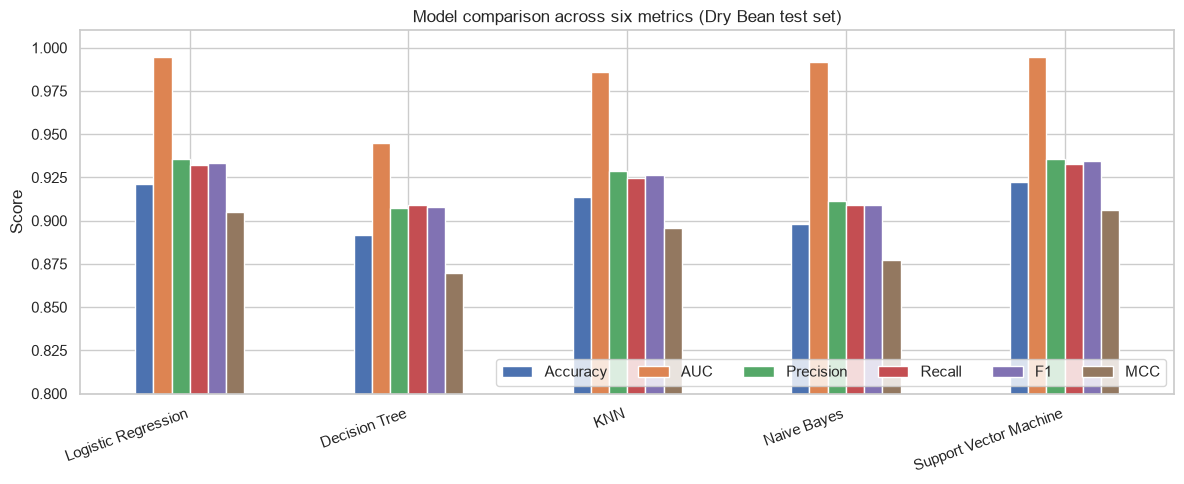

In [10]:
ax = comparison.plot(kind="bar", figsize=(12,5))
plt.title("Model comparison across six metrics (Dry Bean test set)")
plt.ylabel("Score"); plt.ylim(0.80, 1.01)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right", ncol=6)
plt.tight_layout(); plt.show()

## 9. Confusion matrix of the best model

Best model by macro F1: Support Vector Machine


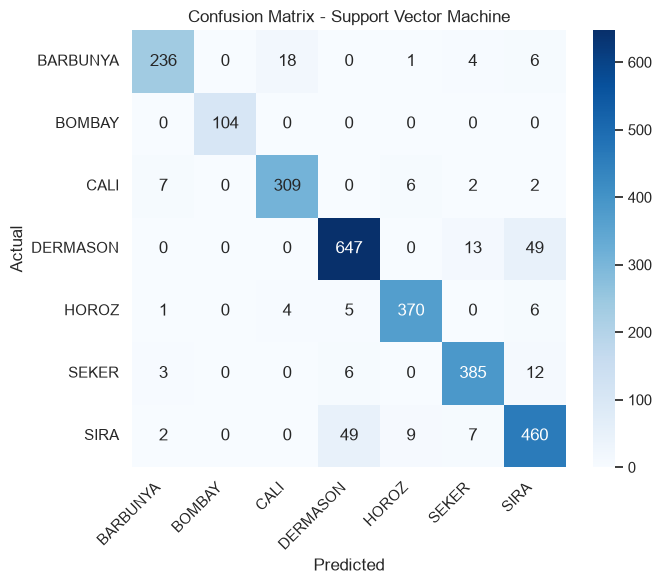

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.86      0.87      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [11]:
best = comparison["F1"].idxmax()
print("Best model by macro F1:", best)
best_model = models[best]
cm = confusion_matrix(y_test, best_model.predict(X_test_scaled))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title(f"Confusion Matrix - {best}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
print(classification_report(y_test, best_model.predict(X_test_scaled),
                            target_names=label_encoder.classes_))

## 10. Export test data for the Streamlit app

The held-out test rows (original, unscaled) plus the `Class` target are written to
`test_data.csv`. This is the file users upload into the deployed Streamlit app.


In [12]:
test_df = X_test.copy()
test_df["Class"] = label_encoder.inverse_transform(y_test)
test_df.to_csv(f"{ROOT}/test_data.csv", index=False)
print("Saved test_data.csv:", test_df.shape)
test_df.head()

Saved test_data.csv: (2723, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
12803,36002,700.889,257.888986,178.268649,1.446631,0.722605,36368,214.100841,0.797386,0.989936,0.920954,0.830205,0.007163,0.002099,0.689241,0.997078,DERMASON
3713,183825,1594.423,582.225240,402.762055,1.445581,0.722124,185116,483.790512,0.797852,0.993026,0.908672,0.830934,0.003167,0.000931,0.690451,0.998102,BOMBAY
8974,45595,801.717,301.092828,193.505323,1.555992,0.766138,46054,240.942643,0.769926,0.990033,0.891425,0.800227,0.006604,0.001670,0.640363,0.996401,SIRA
1743,45084,763.811,261.138204,219.977872,1.187111,0.538882,45425,239.588672,0.773098,0.992493,0.971092,0.917478,0.005792,0.002532,0.841767,0.999271,SEKER
2303,61645,952.199,335.139136,235.843970,1.421021,0.710478,62499,280.158619,0.795522,0.986336,0.854382,0.835947,0.005437,0.001638,0.698808,0.993020,BARBUNYA


## 11. Observations

| Model | Observation |
|---|---|
| **Logistic Regression** | Very strong linear baseline; high AUC (~0.995) - the classes are largely linearly separable after scaling. |
| **Decision Tree** | Lowest scores of the five; a single tree overfits and gives sharper, less smooth boundaries. |
| **KNN** | Strong after scaling (k=7); distance-based so standardisation is essential. |
| **Naive Bayes** | Good despite its feature-independence assumption, which is only partly true (several features are correlated). |
| **Support Vector Machine** | Best overall - highest F1, AUC and MCC; the RBF-kernel margin handles the 7-class geometry well. |

**Winner:** Support Vector Machine (highest macro F1 and MCC on the held-out test set),
with Logistic Regression a very close second.
